In [1]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import itertools
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_ind_from_stats

In [2]:
# load dfs

# OG 7
OD_OG7_summary = pd.read_parquet('OD_OG7_summary.parquet')
act_OG7_summary = pd.read_parquet('act_OG7_summary.parquet')

# OG 8
OD_OG8_summary = pd.read_parquet('OD_OG8_summary.parquet')
act_OG8_summary = pd.read_parquet('act_OG8_summary.parquet')

# ALE 7
OD_ALE7_summary = pd.read_parquet('OD_ALE7_summary.parquet')
act_ALE7_summary = pd.read_parquet('act_ALE7_summary.parquet')

# ALE 8
OD_ALE8_summary = pd.read_parquet('OD_ALE8_summary.parquet')
act_ALE8_summary = pd.read_parquet('act_ALE8_summary.parquet')

# ALE 9
OD_ALE9_summary = pd.read_parquet('OD_ALE9_summary.parquet')
act_ALE9_summary = pd.read_parquet('act_ALE9_summary.parquet')

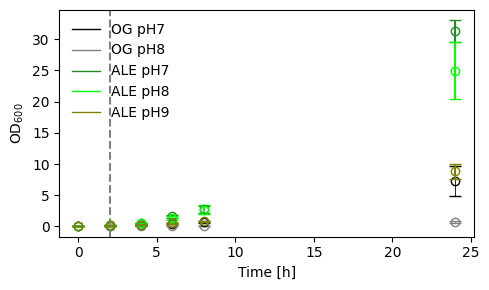

In [3]:
# OD plot
fig, ax = plt.subplots(figsize=(5, 3))

# OG 7
ax.errorbar(OD_OG7_summary.index, OD_OG7_summary["mean_OD"], yerr=OD_OG7_summary["std_OD"],
            fmt='o', linestyle='none', mfc='none', mec='0.0', color='0.0', capsize=4, label="OG pH7",
            elinewidth=0.6, zorder=1)

# OG 8
ax.errorbar(OD_OG8_summary.index, OD_OG8_summary["mean_OD"], yerr=OD_OG8_summary["std_OD"],
            fmt='o', linestyle='none', mfc='none', mec='0.5', color='0.5', capsize=4, label="OG pH 8",
            elinewidth=0.6, zorder=1)

# ALE 7
ax.errorbar(OD_ALE7_summary.index, OD_ALE7_summary["mean_OD"], yerr=OD_ALE7_summary["std_OD"],
            fmt='o', linestyle='none', mfc='none', mec='forestgreen', color='forestgreen', capsize=4, label="ALE pH7")
          
# ALE 8
ax.errorbar(OD_ALE8_summary.index, OD_ALE8_summary["mean_OD"], yerr=OD_ALE8_summary["std_OD"],
            fmt='o', linestyle='none', mfc='none', mec='lime', color='lime', capsize=4, label="ALE pH8")

# ALE 9
ax.errorbar(OD_ALE9_summary.index, OD_ALE9_summary["mean_OD"], yerr=OD_ALE9_summary["std_OD"],
            fmt='o', linestyle='none', mfc='none', mec='olive', color='olive', capsize=4, label="ALE pH9")

legend_handles = [
    Line2D([0], [0], color='0.0', lw=1, label='OG pH7'),
    Line2D([0], [0], color='0.5', lw=1, label='OG pH8'),
    Line2D([0], [0], color='forestgreen', lw=1, label='ALE pH7'),
    Line2D([0], [0], color='lime', lw=1, label='ALE pH8'),
    Line2D([0], [0], color='olive', lw=1, label='ALE pH9')
]

# IPTG line
ax.axvline(x=2, color='0.5', linestyle='--', label='IPTG added')

ax.set_xlabel("Time [h]")
ax.set_ylabel("OD$_{600}$")
#ax.set_title("Growth curve")
ax.legend(handles=legend_handles, frameon=False)
plt.tight_layout()

#plt.savefig("shakeflasks_growth.png", dpi=300, bbox_inches="tight")
plt.show()

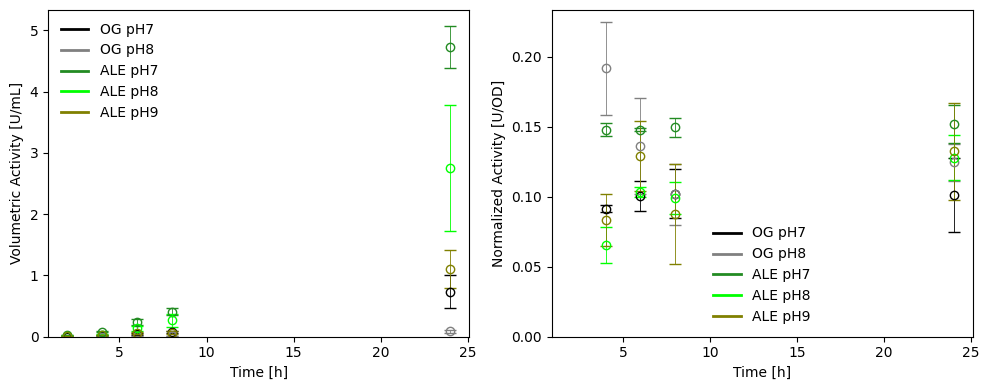

In [ ]:
# activity plot - SUBPLOTS
x = [2, 4, 6, 8, 24]
x_norm = [4, 6, 8, 24]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharex=True)

# ---- Volumetric activity ----
ax1.errorbar(x, act_OG7_summary['vol_mean'], yerr=act_OG7_summary['vol_std'],
             fmt='o', linestyle='none', mfc='none', color='0.0',
             capsize=4, elinewidth=0.6)

ax1.errorbar(x, act_OG8_summary['vol_mean'], yerr=act_OG8_summary['vol_std'],
             fmt='o', linestyle='none', mfc='none', color='0.5',
             capsize=4, elinewidth=0.6)

ax1.errorbar(x, act_ALE7_summary['vol_mean'], yerr=act_ALE7_summary['vol_std'],
             fmt='o', linestyle='none', mfc='none', color='forestgreen',
             capsize=4, elinewidth=0.6)

ax1.errorbar(x, act_ALE8_summary['vol_mean'], yerr=act_ALE8_summary['vol_std'],
             fmt='o', linestyle='none', mfc='none', color='lime',
             capsize=4, elinewidth=0.6)

ax1.errorbar(x, act_ALE9_summary['vol_mean'], yerr=act_ALE9_summary['vol_std'],
             fmt='o', linestyle='none', mfc='none', color='olive',
             capsize=4, elinewidth=0.6)

# ---- Normalized activity ----
# w.o. first datapoint because of inflation when OD is to low
ax2.errorbar(x_norm, act_OG7_summary['norm_mean'][1:], yerr=act_OG7_summary['norm_std'][1:],
             fmt='o', linestyle='none', mfc='none', color='0.0',
             capsize=4, elinewidth=0.6)

ax2.errorbar(x_norm, act_OG8_summary['norm_mean'][1:], yerr=act_OG8_summary['norm_std'][1:],
             fmt='o', linestyle='none', mfc='none', color='0.5',
             capsize=4, elinewidth=0.6)

ax2.errorbar(x_norm, act_ALE7_summary['norm_mean'][1:], yerr=act_ALE7_summary['norm_std'][1:],
             fmt='o', linestyle='none', mfc='none', color='forestgreen',
             capsize=4, elinewidth=0.6)

ax2.errorbar(x_norm, act_ALE8_summary['norm_mean'][1:], yerr=act_ALE8_summary['norm_std'][1:],
             fmt='o', linestyle='none', mfc='none', color='lime',
             capsize=4, elinewidth=0.6)

ax2.errorbar(x_norm, act_ALE9_summary['norm_mean'][1:], yerr=act_ALE9_summary['norm_std'][1:],
             fmt='o', linestyle='none', mfc='none', color='olive',
             capsize=4, elinewidth=0.6)

# ---- Axis formatting ----
ax1.set_xlabel("Time [h]")
ax1.set_ylabel("Volumetric Activity [U/mL]")
ax1.set_ylim(bottom=0)

ax2.set_xlabel("Time [h]")
ax2.set_ylabel("Normalized Activity [U/OD]")
ax2.set_ylim(bottom=0)

# ---- Legends (separate) ----
legend_elements = [
    Line2D([0], [0], color='0.0', lw=2, label='OG pH7'),
    Line2D([0], [0], color='0.5', lw=2, label='OG pH8'),
    Line2D([0], [0], color='forestgreen', lw=2, label='ALE pH7'),
    Line2D([0], [0], color='lime', lw=2, label='ALE pH8'),
    Line2D([0], [0], color='olive', lw=2, label='ALE pH9')
]

ax1.legend(handles=legend_elements, frameon=False)
ax2.legend(handles=legend_elements, frameon=False)

plt.tight_layout()

#plt.savefig("shakeflasks_activity", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# significance testing
# collect values
dfs = {
    "OG7": act_OG7_summary,
    "OG8": act_OG8_summary,
    "ALE7": act_ALE7_summary,
    "ALE8": act_ALE8_summary,
    "ALE9": act_ALE9_summary,
}

def extract_pool5(dfs, prefix):
    data = {}
    for name, df in dfs.items():
        row = df[df[f"{prefix}_pool"] == 5].iloc[0]
        data[name] = {
            "mean": row[f"{prefix}_mean"],
            "std": row[f"{prefix}_std"],
            "n": row[f"{prefix}_n"],
        }
    return data

vol_data = extract_pool5(dfs, "vol")
norm_data = extract_pool5(dfs, "norm")

# pairwise comparisons
def pairwise_tests(data):
    results = []

    for (name1, d1), (name2, d2) in itertools.combinations(data.items(), 2):
        t, p = ttest_ind_from_stats(
            mean1=d1["mean"], std1=d1["std"], nobs1=d1["n"],
            mean2=d2["mean"], std2=d2["std"], nobs2=d2["n"],
            equal_var=False  # Welch
        )

        results.append({
            "group1": name1,
            "group2": name2,
            "p_value": p
        })

    return pd.DataFrame(results)

# run functions
vol_results = pairwise_tests(vol_data)
norm_results = pairwise_tests(norm_data)

# correct for mutiple testing
def adjust_pvalues(df):
    _, p_adj, _, _ = multipletests(df["p_value"], method="holm")
    df["p_adj"] = p_adj
    return df

vol_results = adjust_pvalues(vol_results)
norm_results = adjust_pvalues(norm_results)

OD_dfs = {
    "OG7": OD_OG7_summary,
    "OG8": OD_OG8_summary,
    "ALE7": OD_ALE7_summary,
    "ALE8": OD_ALE8_summary,
    "ALE9": OD_ALE9_summary,
}

def extract_OD_time(dfs, time_h):
    data = {}

    for name, df in dfs.items():
        row = df.loc[time_h]

        data[name] = {
            "mean": row["mean_OD"],
            "std": row["std_OD"],
            "n": 3,
        }

    return data

OD_data = extract_OD_time(OD_dfs, time_h=24)
OD_results = adjust_pvalues(pairwise_tests(OD_data))

# print results
print(vol_results)
print(norm_results)
print(OD_results)

In [6]:
# ---------- plotting helpers ----------
def p_to_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""


def df_to_bracket_pairs(df, xmap, p_col="p_adj"):
    pairs = []

    for _, row in df.iterrows():
        label = row["stars"] if "stars" in df.columns else p_to_stars(row[p_col])
        if label == "":
            continue

        pairs.append((xmap[row["group1"]], xmap[row["group2"]], label))

    return pairs


def add_sig_bracket(ax, x1, x2, y, h, text):
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + h, y + h, y],
        linewidth=1,
        color="black"
    )
    ax.text(
        (x1 + x2) / 2,
        y + h,
        text,
        ha="center",
        va="bottom",
        fontsize=10
    )


def add_sig_brackets_from_pairs(ax, means, stds, bracket_pairs):
    if not bracket_pairs:
        return

    tops = np.array(means, dtype=float) + np.array(stds, dtype=float)
    ymax = np.nanmax(tops)

    base_gap = 0.06 * ymax if ymax > 0 else 0.1
    h = 0.04 * ymax if ymax > 0 else 0.05
    step = 0.12 * ymax if ymax > 0 else 0.1  # vertical spacing between brackets

    for i, (x1, x2, label) in enumerate(bracket_pairs):
        y = ymax + base_gap + i * step
        add_sig_bracket(ax, x1, x2, y, h, label)

    ax.set_ylim(0, ymax + base_gap + len(bracket_pairs) * step + 2 * h)

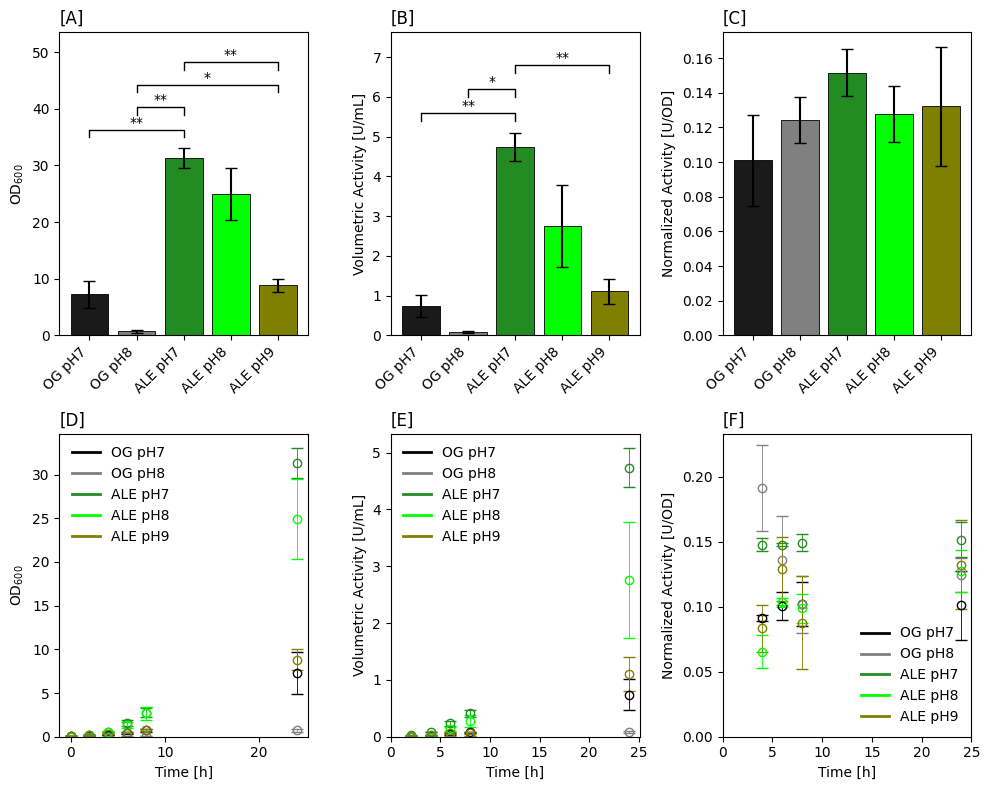

In [ ]:
# time points for activity plots
x = [2, 4, 6, 8, 24]
x_norm = [4, 6, 8, 24]
x_ticks = [0, 5, 10, 15, 20, 25]

# ---------------- Figure layout ----------------
fig, axs = plt.subplots(2, 3, figsize=(10, 8))

ax_A = axs[0, 0]   # OD endpoint
ax_B = axs[0, 1]   # volumetric endpoint
ax_C = axs[0, 2]   # normalized endpoint
ax_D = axs[1, 0]   # OD over time
ax_E = axs[1, 1]   # volumetric over time
ax_F = axs[1, 2]   # normalized over time

# ---------------- Common styling ----------------
groups = ['OG pH7', 'OG pH8', 'ALE pH7', 'ALE pH8', 'ALE pH9']
colors = ['0.1', '0.5', 'forestgreen', 'lime', 'olive']
xpos = np.arange(len(groups))

legend_elements = [
    Line2D([0], [0], color='0.0', lw=2, label='OG pH7'),
    Line2D([0], [0], color='0.5', lw=2, label='OG pH8'),
    Line2D([0], [0], color='forestgreen', lw=2, label='ALE pH7'),
    Line2D([0], [0], color='lime', lw=2, label='ALE pH8'),
    Line2D([0], [0], color='olive', lw=2, label='ALE pH9')
]

# ---------------- A: OD endpoint ----------------
OD_means = [
    OD_OG7_summary.loc[24, "mean_OD"],
    OD_OG8_summary.loc[24, "mean_OD"],
    OD_ALE7_summary.loc[24, "mean_OD"],
    OD_ALE8_summary.loc[24, "mean_OD"],
    OD_ALE9_summary.loc[24, "mean_OD"],
]

OD_stds = [
    OD_OG7_summary.loc[24, "std_OD"],
    OD_OG8_summary.loc[24, "std_OD"],
    OD_ALE7_summary.loc[24, "std_OD"],
    OD_ALE8_summary.loc[24, "std_OD"],
    OD_ALE9_summary.loc[24, "std_OD"],
]

ax_A.bar(xpos, OD_means, yerr=OD_stds, capsize=4, color=colors, edgecolor='black', linewidth=0.6)
ax_A.set_xticks(xpos)
ax_A.set_xticklabels(groups, rotation=45, ha='right')
ax_A.set_ylabel("OD$_{600}$")
ax_A.set_title('[A]', loc='left')
ax_A.set_ylim(bottom=0)

# ---------------- B: volumetric endpoint ----------------
vol_means = [
    act_OG7_summary['vol_mean'].iloc[-1],
    act_OG8_summary['vol_mean'].iloc[-1],
    act_ALE7_summary['vol_mean'].iloc[-1],
    act_ALE8_summary['vol_mean'].iloc[-1],
    act_ALE9_summary['vol_mean'].iloc[-1],
]

vol_stds = [
    act_OG7_summary['vol_std'].iloc[-1],
    act_OG8_summary['vol_std'].iloc[-1],
    act_ALE7_summary['vol_std'].iloc[-1],
    act_ALE8_summary['vol_std'].iloc[-1],
    act_ALE9_summary['vol_std'].iloc[-1],
]

ax_B.bar(xpos, vol_means, yerr=vol_stds, capsize=4, color=colors, edgecolor='black', linewidth=0.6)
ax_B.set_xticks(xpos)
ax_B.set_xticklabels(groups, rotation=45, ha='right')
ax_B.set_ylabel("Volumetric Activity [U/mL]")
ax_B.set_title('[B]', loc='left')
ax_B.set_ylim(bottom=0)

# ---------------- C: normalized endpoint ----------------
norm_means = [
    act_OG7_summary['norm_mean'].iloc[-1],
    act_OG8_summary['norm_mean'].iloc[-1],
    act_ALE7_summary['norm_mean'].iloc[-1],
    act_ALE8_summary['norm_mean'].iloc[-1],
    act_ALE9_summary['norm_mean'].iloc[-1],
]

norm_stds = [
    act_OG7_summary['norm_std'].iloc[-1],
    act_OG8_summary['norm_std'].iloc[-1],
    act_ALE7_summary['norm_std'].iloc[-1],
    act_ALE8_summary['norm_std'].iloc[-1],
    act_ALE9_summary['norm_std'].iloc[-1],
]

ax_C.bar(xpos, norm_means, yerr=norm_stds, capsize=4, color=colors, edgecolor='black', linewidth=0.6)
ax_C.set_xticks(xpos)
ax_C.set_xticklabels(groups, rotation=45, ha='right')
ax_C.set_ylabel("Normalized Activity [U/OD]")
ax_C.set_title('[C]', loc='left')
ax_C.set_ylim(bottom=0)

# ---------------- significance brackets for A, B, and C ----------------

# x-position mapping must match bar order:
# groups = ['OG pH7', 'OG pH8', 'ALE pH7', 'ALE pH8', 'ALE pH9']

xmap = {
    "OG7": 0,
    "OG8": 1,
    "ALE7": 2,
    "ALE8": 3,
    "ALE9": 4,
}

# Convert pairwise results tables to bracket instructions
vol_bracket_pairs = df_to_bracket_pairs(vol_results, xmap, p_col="p_adj")
norm_bracket_pairs = df_to_bracket_pairs(norm_results, xmap, p_col="p_adj")
OD_bracket_pairs = df_to_bracket_pairs(OD_results, xmap, p_col="p_adj")

# Draw brackets
add_sig_brackets_from_pairs(ax_B, vol_means, vol_stds, vol_bracket_pairs)
add_sig_brackets_from_pairs(ax_C, norm_means, norm_stds, norm_bracket_pairs)
add_sig_brackets_from_pairs(ax_A, OD_means, OD_stds, OD_bracket_pairs)

# ---------------- D: OD over time ----------------
ax_D.errorbar(OD_OG7_summary.index, OD_OG7_summary["mean_OD"], yerr=OD_OG7_summary["std_OD"],
              fmt='o', linestyle='none', mfc='none', mec='0.0', color='0.0', capsize=4,
              elinewidth=0.6, zorder=1)

ax_D.errorbar(OD_OG8_summary.index, OD_OG8_summary["mean_OD"], yerr=OD_OG8_summary["std_OD"],
              fmt='o', linestyle='none', mfc='none', mec='0.5', color='0.5', capsize=4,
              elinewidth=0.6, zorder=1)

ax_D.errorbar(OD_ALE7_summary.index, OD_ALE7_summary["mean_OD"], yerr=OD_ALE7_summary["std_OD"],
              fmt='o', linestyle='none', mfc='none', mec='forestgreen', color='forestgreen',
              capsize=4, elinewidth=0.6, zorder=1)

ax_D.errorbar(OD_ALE8_summary.index, OD_ALE8_summary["mean_OD"], yerr=OD_ALE8_summary["std_OD"],
              fmt='o', linestyle='none', mfc='none', mec='lime', color='lime',
              capsize=4, elinewidth=0.6, zorder=1)

ax_D.errorbar(OD_ALE9_summary.index, OD_ALE9_summary["mean_OD"], yerr=OD_ALE9_summary["std_OD"],
              fmt='o', linestyle='none', mfc='none', mec='olive', color='olive',
              capsize=4, elinewidth=0.6, zorder=1)

ax_D.set_xlabel("Time [h]")
ax_D.set_ylabel("OD$_{600}$")
ax_D.set_title('[D]', loc='left')
ax_D.set_ylim(bottom=0)
ax_D.legend(handles=legend_elements, frameon=False)

# ---------------- E: volumetric activity over time ----------------
ax_E.errorbar(x, act_OG7_summary['vol_mean'], yerr=act_OG7_summary['vol_std'],
              fmt='o', linestyle='none', mfc='none', mec='0.0', color='0.0', capsize=4, elinewidth=0.6)

ax_E.errorbar(x, act_OG8_summary['vol_mean'], yerr=act_OG8_summary['vol_std'],
              fmt='o', linestyle='none', mfc='none', mec='0.5', color='0.5', capsize=4, elinewidth=0.6)

ax_E.errorbar(x, act_ALE7_summary['vol_mean'], yerr=act_ALE7_summary['vol_std'],
              fmt='o', linestyle='none', mfc='none', mec='forestgreen', color='forestgreen', capsize=4, elinewidth=0.6)

ax_E.errorbar(x, act_ALE8_summary['vol_mean'], yerr=act_ALE8_summary['vol_std'],
              fmt='o', linestyle='none', mfc='none', mec='lime', color='lime', capsize=4, elinewidth=0.6)

ax_E.errorbar(x, act_ALE9_summary['vol_mean'], yerr=act_ALE9_summary['vol_std'],
              fmt='o', linestyle='none', mfc='none', mec='olive', color='olive', capsize=4, elinewidth=0.6)

ax_E.set_xlabel("Time [h]")
ax_E.set_xticks(x_ticks)
ax_E.set_xticklabels(x_ticks)
ax_E.set_ylabel("Volumetric Activity [U/mL]")
ax_E.set_title('[E]', loc='left')
ax_E.set_ylim(bottom=0)
ax_E.legend(handles=legend_elements, frameon=False)

# ---------------- F: normalized activity over time ----------------
ax_F.errorbar(x_norm, act_OG7_summary['norm_mean'][1:], yerr=act_OG7_summary['norm_std'][1:],
              fmt='o', linestyle='none', mfc='none', mec='0.0', color='0.0', capsize=4, elinewidth=0.6)

ax_F.errorbar(x_norm, act_OG8_summary['norm_mean'][1:], yerr=act_OG8_summary['norm_std'][1:],
              fmt='o', linestyle='none', mfc='none', mec='0.5', color='0.5', capsize=4, elinewidth=0.6)

ax_F.errorbar(x_norm, act_ALE7_summary['norm_mean'][1:], yerr=act_ALE7_summary['norm_std'][1:],
              fmt='o', linestyle='none', mfc='none', mec='forestgreen', color='forestgreen', capsize=4, elinewidth=0.6)

ax_F.errorbar(x_norm, act_ALE8_summary['norm_mean'][1:], yerr=act_ALE8_summary['norm_std'][1:],
              fmt='o', linestyle='none', mfc='none', mec='lime', color='lime', capsize=4, elinewidth=0.6)

ax_F.errorbar(x_norm, act_ALE9_summary['norm_mean'][1:], yerr=act_ALE9_summary['norm_std'][1:],
              fmt='o', linestyle='none', mfc='none', mec='olive', color='olive', capsize=4, elinewidth=0.6)

ax_F.set_xlabel("Time [h]")
ax_F.set_xticks(x_ticks)
ax_F.set_xticklabels(x_ticks)
ax_F.set_ylabel("Normalized Activity [U/OD]")
ax_F.set_title('[F]', loc='left')
ax_F.set_ylim(bottom=0)
ax_F.legend(handles=legend_elements, frameon=False)

plt.tight_layout()

#plt.savefig("batch_runs.png", dpi=300, bbox_inches="tight")
plt.show()